In [ ]:
# Install YOLOv8
!pip install ultralytics -q


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.0/1.0 MB 38.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 363.4/363.4 MB 5.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.8/13.8 MB 114.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 24.6/24.6 MB 85.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 883.7/883.7 kB 48.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 664.8/664.8 MB 2.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 211.5/211.5 MB 5.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 56.3/56.3 MB 12.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 127.9/127.9 MB 7.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 207.5/207.5 MB 5.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 21.1/21.1 MB 68.9 MB/s eta 0:00:00


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

In [ ]:
#Mount Google Drive
from google.colab import drive
drive.mount('/content/drive')



Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
#Import Libraries
from ultralytics import YOLO
from IPython.display import Image, display
from pathlib import Path
import shutil



Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.


In [ ]:
#Define the path to your image folder
image_folder = "/content/drive/MyDrive/Colab Notebooks/dataset/images"

#Load YOLOv8 Model
model = YOLO("yolov8n.pt")



100%|██████████| 6.25M/6.25M [00:00<00:00, 102MB/s]


Streaming output truncated to the last 5000 lines.
image 17246/22241 /content/drive/MyDrive/Colab Notebooks/dataset/images/1479502279730506173.jpg: 416x640 5 cars, 2 traffic lights, 152.5ms
image 17247/22241 /content/drive/MyDrive/Colab Notebooks/dataset/images/1479502280230536426.jpg: 416x640 7 cars, 3 traffic lights, 151.2ms
image 17248/22241 /content/drive/MyDrive/Colab Notebooks/dataset/images/1479502280730839737.jpg: 416x640 6 cars, 2 traffic lights, 156.7ms
image 17249/22241 /content/drive/MyDrive/Colab Notebooks/dataset/images/1479502281729824146.jpg: 416x640 5 cars, 3 traffic lights, 158.9ms
image 17250/22241 /content/drive/MyDrive/Colab Notebooks/dataset/images/1479502282229848985.jpg: 416x640 4 cars, 3 traffic lights, 163.7ms
image 17251/22241 /content/drive/MyDrive/Colab Notebooks/dataset/images/1479502282730102580.jpg: 416x640 5 cars, 2 traffic lights, 152.4ms
image 17252/22241 /content/drive/MyDrive/Colab Notebooks/dataset/images/1479502283731724690.jpg: 416x640 7 cars, 2 

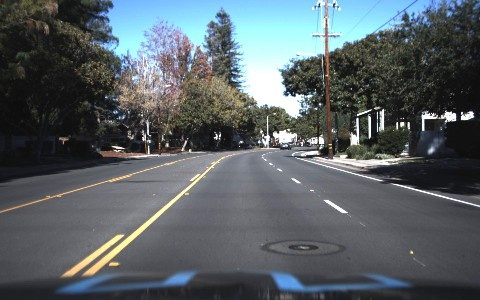

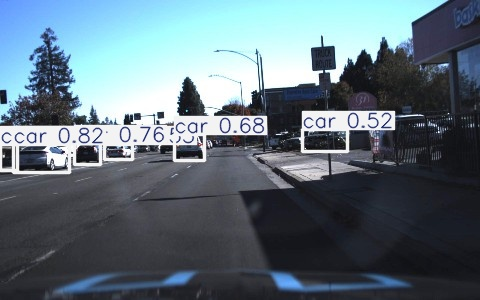

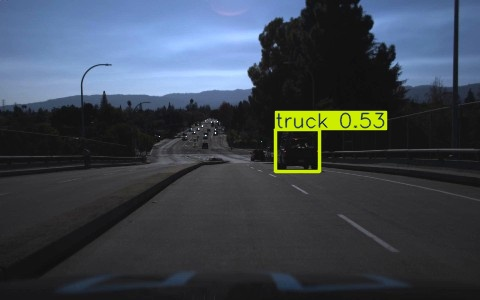

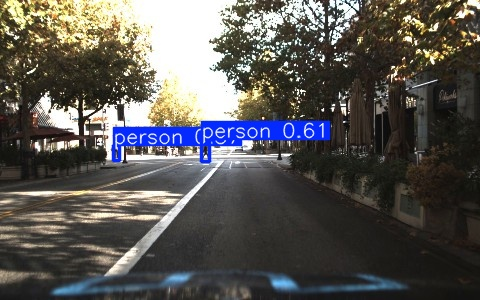

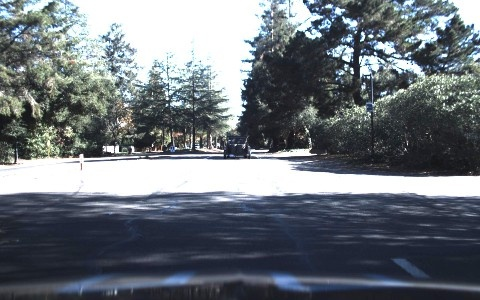

In [ ]:
#Run Object Detection
results = model.predict(
    source=image_folder,
    save=True,
    project="runs/detect",
    name="traffic_detect_drive",
    conf=0.3
)

#Display First Few Detected Images
output_path = Path("runs/detect/traffic_detect_drive")
image_files = list(output_path.glob("*.jpg")) + list(output_path.glob("*.png"))

print(f"\n Displaying {min(5, len(image_files))} results from {output_path}:")
for image_path in image_files[:5]:
    display(Image(filename=str(image_path)))

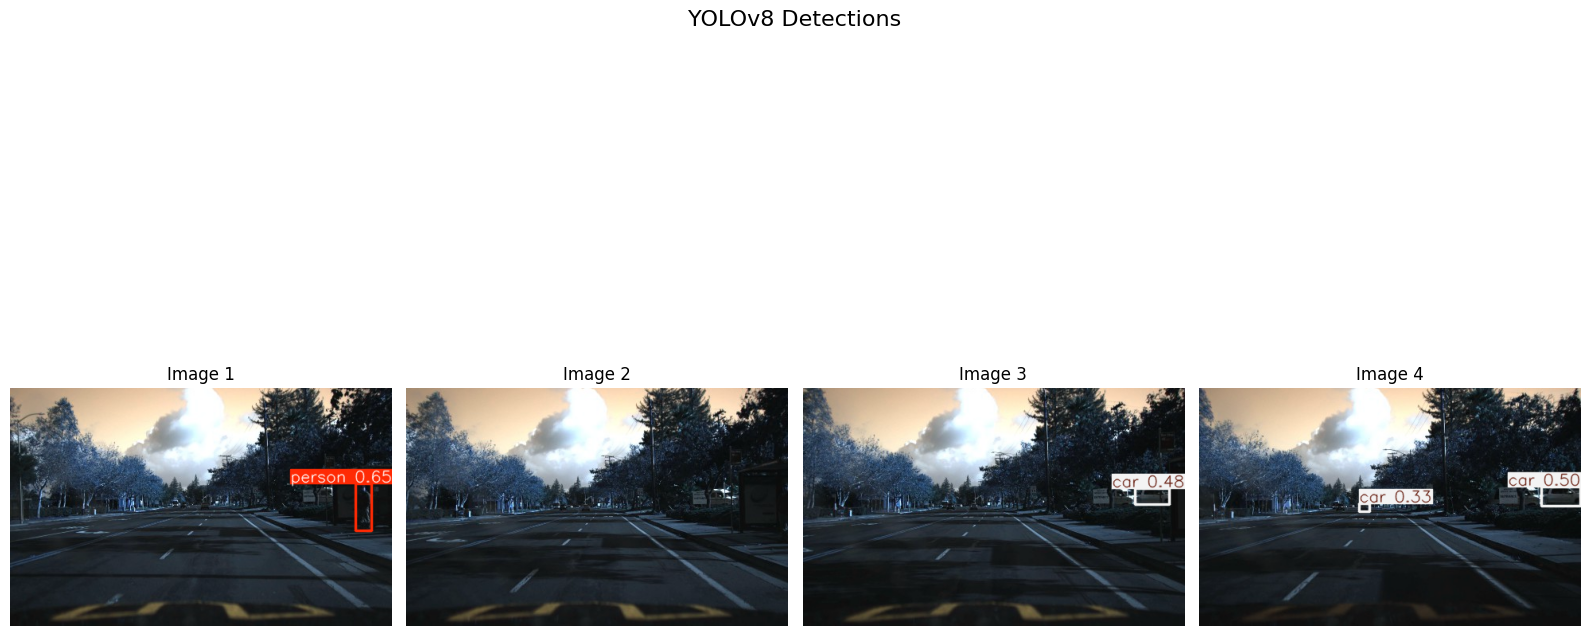

In [ ]:
import matplotlib.pyplot as plt

num_images = min(4, len(results))

plt.figure(figsize=(16, 10))

for i in range(num_images):
    img = results[i].plot()
    plt.subplot(1, num_images, i + 1)
    plt.imshow(img)
    plt.axis("off")
    plt.title(f"Image {i+1}")

plt.suptitle("YOLOv8 Detections", fontsize=16)
plt.tight_layout()
plt.show()


In [ ]:
!cp -r /content/runs/detect/traffic_detect_drive "/content/drive/MyDrive/Colab Notebooks/detected_traffic/"
